In [1]:
import firedrake
import numpy as np
import pickle as pkl
from numpy import pi as π
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from firedrake import *
from firedrake import Constant, inner, sqrt, tr, grad, div, as_vector, exp,sym, as_vector, dx, ds, Mesh, Function, project, TransferManager, RectangleMesh, ExtrudedMesh, FunctionSpace, Function, SpatialCoordinate, FiniteElement
import meshpy, meshpy.geometry, meshpy.triangle
import irksome
from irksome import Dt
from scipy.signal import detrend
import copy
import matplotlib
import irksome
from irksome import Dt
import matplotlib.pyplot as plt
import pandas as pd
import scipy
import pickle as pkl
import tqdm
import emcee
import corner
import itertools
import xarray
import dtscalibration
import glob
from rasterio.plot import show
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import os
import sys
from pyproj import Transformer
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from scripts.AH_temp_funcs import *

from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import shapefile as sf

import rasterio
from rasterio.enums import Resampling
from rasterio.mask import mask

import irksome
from irksome import Dt
from collections import defaultdict, OrderedDict

from matplotlib.gridspec import GridSpec

### Import our homemade functions ###
import scripts.model_modules
from scripts.mesh_generating import *

import string

%matplotlib widget

In [2]:
upscale_factor_fine = 1/10
src_bed_fine_path = "Meshes/crop_aoi/main_boreholes_aoi/main_boreholes_aoi_fix_bed.tif"
src_surf_fine_path = "Meshes/crop_aoi/main_boreholes_aoi/main_boreholes_aoi_fix_surf.tif"
layer_num=5

In [3]:
mesh_fine = mesh_creator(src_bed_fine_path, src_surf_fine_path, resamp_factor=upscale_factor_fine, layers=layer_num)
mesh_fine.tolerance = 1e-10
x_src, y_src, z_src = SpatialCoordinate(mesh_fine)

pressure_space = firedrake.FunctionSpace(mesh_fine, "CG", 1)
velocity_space = firedrake.VectorFunctionSpace(mesh_fine, "CG", 3)
Y = velocity_space * pressure_space
flow = firedrake.Function(Y)

# chk = DumbCheckpoint("Saved_Models/fine_mesh_flow_80.0m_updated_viscosity", mode=FILE_READ)
# chk.load(flow, name="fine_mesh_flow")

chk = DumbCheckpoint("Saved_Models/fine_mesh_flow_80.0m_updated_viscosity", mode=FILE_READ)
chk.load(flow, name="fine_mesh_flow")

enhancement_factor = 1.97

flow.dat.data_wo[0][:] = flow.dat.data_ro[0][:]*enhancement_factor

# new_vel = firedrake.Function(velocity_space)
# new_vel.interpolate(flow.dat.data_ro[0]*1.97)
u,p = firedrake.split(flow)


/opt/firedrake/firedrake/checkpointing.py:103: DeprecationWarning: DumbCheckpoint class will soon be deprecated; use CheckpointFile class instead.
  warnings.warn("DumbCheckpoint class will soon be deprecated; use CheckpointFile class instead.",


In [ ]:
surface_coords = []

for x_coord in np.unique(mesh_fine.coordinates.dat.data_ro[:,0]):
    for y_coord in np.unique(mesh_fine.coordinates.dat.data_ro[:,1]):
        zs_of_coord = []
        for coord in mesh_fine.coordinates.dat.data_ro:
            if coord[0] == x_coord and coord[1] == y_coord:
                zs_of_coord.append(coord[2])
        z_surf = np.array(zs_of_coord).max()
        surface_coords.append([x_coord,y_coord, z_surf])

In [ ]:
x_coords_grid = np.array(surface_coords)[:,0].reshape(65,71)
y_coords_grid = np.array(surface_coords)[:,1].reshape(65,71)
z_coords_grid = np.array(surface_coords)[:,2].reshape(65,71)

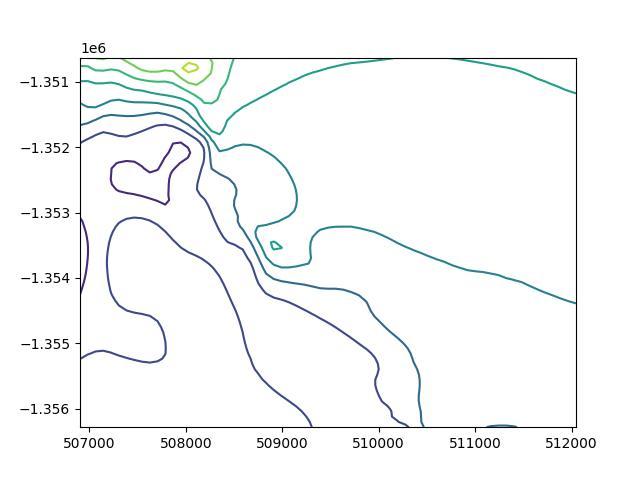

In [ ]:
fig,ax = plt.subplots()

ax.contour(x_coords_grid, y_coords_grid, z_coords_grid)

In [ ]:
zy, zx = np.gradient(z_coords_grid, x_coords_grid[:,0], y_coords_grid[0,:])  
# You may also consider using Sobel to get a joint Gaussian smoothing and differentation
# to reduce noise
#zx = cv2.Sobel(d_im, cv2.CV_64F, 1, 0, ksize=5)     
#zy = cv2.Sobel(d_im, cv2.CV_64F, 0, 1, ksize=5)

normal = np.dstack((-zx, -zy, np.ones_like(z_coords_grid)))
n = np.linalg.norm(normal, axis=2)
normal[:, :, 0] /= n
normal[:, :, 1] /= n
normal[:, :, 2] /= n


AttributeError: Line3DCollection.set() got an unexpected keyword argument 'scale'

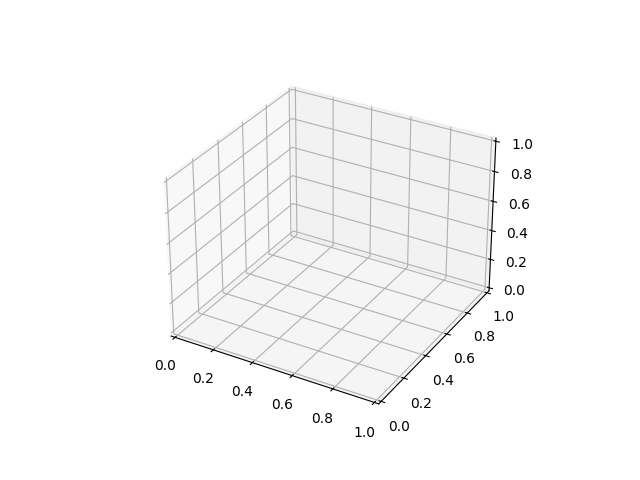

In [ ]:
ax = plt.figure().add_subplot(projection='3d')

ax.quiver(x_coords_grid, y_coords_grid, z_coords_grid, normal[:, :, 0], normal[:, :, 1], normal[:, :, 2], scale = .1)

In [ ]:
enhancement_factor=1.97


surf_velocities = []

for x_surf_coord, y_surf_coord, z_surf_coord in surface_coords:
    try:
        velocity_model = flow.at((x_surf_coord, y_surf_coord, z_surf_coord))[0] * enhancement_factor

        surf_velocities.append(velocity_model)
    except:
        continue


In [ ]:
surf_velocities_arr = np.array(surf_velocities).reshape((65,71, 3))

In [ ]:
accum_assumed = np.zeros(surf_velocities_arr.shape[:2])
for row_id in range(accum_assumed.shape[0]):
    for col_id in range(accum_assumed.shape[1]):
        accum_assumed[row_id, col_id] = np.dot(surf_velocities_arr[row_id, col_id], normal[row_id, col_id]) - surf_velocities_arr[row_id, col_id][-1]

In [ ]:
accum_assumed_mmyr = accum_assumed * spy * 1000

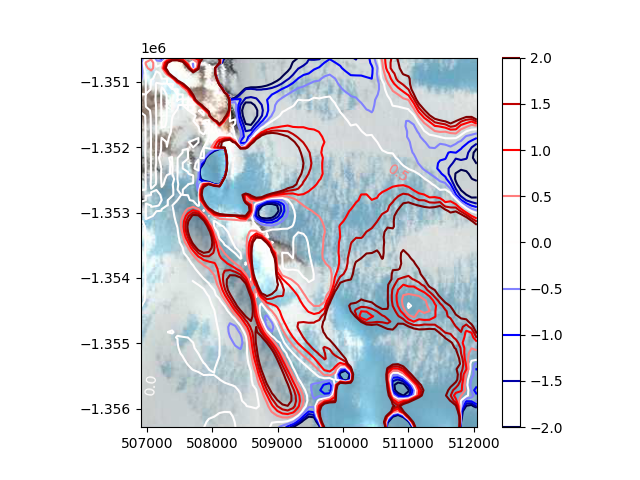

In [ ]:
fig,ax = plt.subplots()

with rasterio.open('imagery/LIMA_virtual_Mosaic_15m.tif') as src1:
    image_data = src1.read()
show(image_data,ax=ax,transform=src1.transform)
CS= ax.contour(x_coords_grid, y_coords_grid,accum_assumed_mmyr, levels = [-2,-1.5,-1,-0.5,0,.5,1,1.5,2], cmap="seismic")
ax.clabel(CS, fontsize=10)
ax.set_ylim([y_coords_grid.min(), y_coords_grid.max()])
ax.set_xlim([x_coords_grid.min(), x_coords_grid.max()])
plt.colorbar(CS)

In [22]:
np.sum(accum_assumed_mmyr)

np.float64(9075.90428515129)